In [1]:
pip install flatland-rl

Defaulting to user installation because normal site-packages is not writeable
You should consider upgrading via the '/Library/Developer/CommandLineTools/usr/bin/python3 -m pip install --upgrade pip' command.
Note: you may need to restart the kernel to use updated packages.


In [1]:
import numpy as np
import time
from flatland.envs.rail_env import RailEnv
from flatland.envs.rail_generators import sparse_rail_generator
from flatland.envs.line_generators import sparse_line_generator
from flatland.envs.observations import GlobalObsForRailEnv

def main():
    # Parameters for the environment
    n_agents = 3
    x_dim = 35
    y_dim = 35
    n_cities = 2
    max_rails_between_cities = 2
    max_rail_pairs_in_city = 3
    seed = 42

    # Rail generator
    rail_generator = sparse_rail_generator(
        max_num_cities=n_cities,
        grid_mode=False,
        max_rails_between_cities=max_rails_between_cities,
        max_rail_pairs_in_city=max_rail_pairs_in_city,
        seed=seed
    )

    # Line generator (Schedule generator)
    line_generator = sparse_line_generator()

    # Create the environment
    env = RailEnv(
        width=x_dim,
        height=y_dim,
        rail_generator=rail_generator,
        line_generator=line_generator,
        number_of_agents=n_agents,
        obs_builder_object=GlobalObsForRailEnv()
    )

    # Reset the environment
    obs, info = env.reset()

    print(f"Environment initialized with {n_agents} agents.")
    print(f"Grid size: {x_dim}x{y_dim}")

    # Run for a few steps
    for step in range(10):
        print(f"\n--- Step {step} ---")
        
        # Select random actions for each agent
        actions = {}
        for agent_idx in range(n_agents):
            # 0: DO NOTHING, 1: LEFT, 2: FORWARD, 3: RIGHT, 4: STOP
            action = np.random.randint(0, 5)
            actions[agent_idx] = action
            print(f"Agent {agent_idx} action: {action}")

        # Step the environment
        next_obs, rewards, done, info = env.step(actions)

        # Check if all agents are finished
        if done['__all__']:
            print("All agents reached their destinations!")
            break

        # Small delay to keep it readable
        time.sleep(0.1)

    print("\nDemo finished.")

In [2]:
main()

Environment initialized with 3 agents.
Grid size: 35x35

--- Step 0 ---
Agent 0 action: 2
Agent 1 action: 3
Agent 2 action: 2

--- Step 1 ---
Agent 0 action: 1
Agent 1 action: 0
Agent 2 action: 1

--- Step 2 ---
Agent 0 action: 3
Agent 1 action: 4
Agent 2 action: 2

--- Step 3 ---
Agent 0 action: 0
Agent 1 action: 1
Agent 2 action: 1

--- Step 4 ---
Agent 0 action: 3
Agent 1 action: 0
Agent 2 action: 3

--- Step 5 ---
Agent 0 action: 0
Agent 1 action: 0
Agent 2 action: 0

--- Step 6 ---
Agent 0 action: 3
Agent 1 action: 4
Agent 2 action: 3

--- Step 7 ---
Agent 0 action: 0
Agent 1 action: 2
Agent 2 action: 0

--- Step 8 ---
Agent 0 action: 0
Agent 1 action: 2
Agent 2 action: 0

--- Step 9 ---
Agent 0 action: 0
Agent 1 action: 4
Agent 2 action: 2

Demo finished.


In [5]:
from flatland.envs.rail_env import RailEnv
from flatland.envs.rail_generators import sparse_rail_generator
from flatland.envs.line_generators import sparse_line_generator
from flatland.envs.observations import GlobalObsForRailEnv


rail_generator = sparse_rail_generator(max_num_cities=2,grid_mode=True)

# Initialize the properties of the environment
random_env = RailEnv(
    width=24,
    height=24,
    number_of_agents=1,
    rail_generator=rail_generator,
    line_generator=sparse_line_generator(),
    obs_builder_object=GlobalObsForRailEnv()
)

# Call reset() to initialize the environment
observation, info = random_env.reset()

In [6]:
import PIL
from flatland.utils.rendertools import RenderTool
from IPython.display import clear_output

def render_env(env,wait=True, env_renderer = None):
    if env_renderer is None:
        env_renderer = RenderTool(env)
    env_renderer.render_env()
    image = env_renderer.get_image()
    pil_image = PIL.Image.fromarray(image)
    clear_output(wait=True)
    display(pil_image)

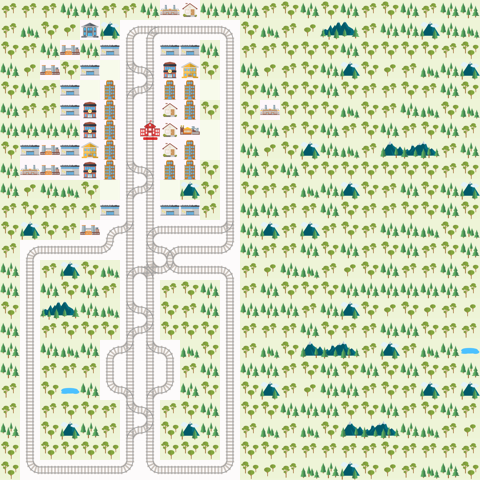

In [7]:
render_env(random_env)

In [8]:
transitions_obj = random_env.rail.transitions
print(transitions_obj.transition_list)

[0, 32800, 37408, 33825, 38433, 52275, 20994, 8192, 16386, 4608, 49186]


In [18]:
import numpy as np

for agent_handle in random_env.get_agent_handles():
    print('Observations for agent {}:'.format(agent_handle))
    agent_obs = observation[agent_handle]

    print('- Transition map\n{}\n'.format(np.transpose(agent_obs[0], (2, 0, 1))))
    print('- Agent position\n{}\n'.format(np.transpose(agent_obs[1], (2, 0, 1))))
    print('- Agent target \n{}\n'.format(np.transpose(agent_obs[2], (2, 0, 1))))

Observations for agent 0:
- Transition map
[[[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 ...

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]]

 [[0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0. 0.]
  ...
  [0. 0. 0. ... 0. 0. 0.]
  [0. 0. 0. ... 0. 0.

In [19]:
class RandomController:
    def __init__(self, action_size):
        self.action_size = action_size

    def act(self, observations):
        actions = dict()
        for agent_handle, observation in enumerate(observations):
            action = np.random.randint(self.action_size)
            actions.update({agent_handle: action})
        return actions

In [20]:
from flatland.envs.rail_env import RailEnvActions

controller = RandomController(random_env.action_space[0])
observations, info = random_env.reset()
actions = controller.act(observations)

# Perform a single action per agent
for (handle, action) in actions.items():
    print('Agent {} will perform action {} ({})'.format(handle, action, RailEnvActions.to_char(action)))
    next_obs, all_rewards, dones, info = random_env.step({handle: action})

print('Rewards for each agent: {}'.format(all_rewards))
print('Done for each agent: {}'.format(dones))
print('Misc info: {}'.format(info))

Agent 0 will perform action 4 (S)
Agent 1 will perform action 4 (S)
Agent 2 will perform action 1 (L)
Rewards for each agent: {0: 0, 1: 0, 2: 0}
Done for each agent: {0: False, 1: False, 2: False, '__all__': False}
Misc info: {'action_required': {0: True, 1: False, 2: False}, 'malfunction': {0: 0, 1: 0, 2: 0}, 'speed': {0: 1.0, 1: 1.0, 2: 1.0}, 'state': {0: <TrainState.READY_TO_DEPART: 1>, 1: <TrainState.WAITING: 0>, 2: <TrainState.WAITING: 0>}}


In [21]:
def run_episode(env):
    env_renderer = RenderTool(env)
    controller = RandomController(env.action_space[0])
    observations, info = env.reset()

    score = 0
    actions = dict()

    for step in range(50):

        actions = controller.act(observations)
        next_observations, all_rewards, dones, info = env.step(actions)
        for agent_handle in env.get_agent_handles():
            score += all_rewards[agent_handle]

        , env_renderer=env_rendererrender_env(env)
        print('Timestep {}, total score = {}'.format(step, score))

        if dones['__all__']:
            print('All done!')
            return

    print("Episode didn't finish after 50 timesteps.")

In [22]:
run_episode(random_env)

Timestep 0, total score = 0
Timestep 1, total score = 0
Timestep 2, total score = 0
Timestep 3, total score = 0
Timestep 4, total score = 0
Timestep 5, total score = 0
Timestep 6, total score = 0
Timestep 7, total score = 0
Timestep 8, total score = 0
Timestep 9, total score = 0
Timestep 10, total score = 0
Timestep 11, total score = 0
Timestep 12, total score = 0
Timestep 13, total score = 0
Timestep 14, total score = 0
Timestep 15, total score = 0
Timestep 16, total score = 0
Timestep 17, total score = 0
Timestep 18, total score = 0
Timestep 19, total score = 0
Timestep 20, total score = 0
Timestep 21, total score = 0
Timestep 22, total score = 0
Timestep 23, total score = 0
Timestep 24, total score = 0
Timestep 25, total score = 0
Timestep 26, total score = 0
Timestep 27, total score = 0
Timestep 28, total score = 0
Timestep 29, total score = 0
Timestep 30, total score = 0
Timestep 31, total score = 0
Timestep 32, total score = 0
Timestep 33, total score = 0
Timestep 34, total score

In [26]:
import flatland
print(flatland.__version__)

4.0.3


In [31]:
from flatland.core.transitions import Grid4Transitions


ImportError: cannot import name 'Grid4Transitions' from 'flatland.core.transitions' (/Users/shashwatt/Library/Python/3.9/lib/python/site-packages/flatland/core/transitions.py)

In [10]:
from flatland.core.grid.rail_env_grid import RailEnvTransitions
print(RailEnvTransitions().transitions_all)

{0, 32800, 1025, 37408, 3089, 32872, 17411, 33825, 38433, 35889, 33897, 50211, 52275, 38505, 20994, 6672, 2136, 16458, 8192, 256, 128, 4, 16386, 4608, 2064, 72, 49186, 5633, 34864, 1097}


In [1]:
try:
    import google.colab
    print("Connected to Colab!")
except ImportError:
    print("Running Locally.")


Connected to Colab!
